# Exploratory Data Analysis: Data Centre Load Profiles

**Goal of this notebook:** understand the data well enough to decide how to forecast it. Each section asks one question, answers it with a table or chart, and ends with a **Takeaway** that feeds into the modelling decisions summarised at the end.

**The dataset in one paragraph.** Hourly records for 6 synthetic data centre sites over 3 months (1 May to 31 July 2018), all using weather from Syracuse, New York. Each row is one site in one hour, with:
- how much power the site drew, split into IT (servers), cooling and other
- how efficiently it ran (PUE)
- the weather
- calendar information

Source: Bohluli Oskouei, Eftekharnejad and Mohan, IEEE DataPort, [doi:10.21227/9hb2-de87](https://doi.org/10.21227/9hb2-de87), CC BY 4.0.

**Key terms**
- **MW (megawatt):** power at a moment. A site drawing 60 MW for one hour uses 60 MWh of energy.
- **IT load:** power used by servers, storage and network equipment. This is the useful work.
- **PUE (Power Usage Effectiveness)** = total power ÷ IT power. A PUE of 1.40 means 0.40 MW of overhead (mostly cooling) for every 1 MW of IT. Lower is better, and 1.0 would be perfect.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

# One fixed colour per site, used in every chart, so a site keeps its colour throughout.
SITE_COLORS = {
    "SITE_001": "#2a78d6", "SITE_002": "#eb6834", "SITE_003": "#1baf7a",
    "SITE_004": "#eda100", "SITE_005": "#e87ba4", "SITE_006": "#008300",
}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlelocation": "left",
    "axes.titlesize": 12, "axes.titlecolor": INK, "legend.frameon": False, "figure.dpi": 110,
})

## 1. First look

Load the file and check its size, column types and a few rows.

In [2]:
df = pd.read_csv("../data/raw/3-Month Data Center Load Profiles.csv", parse_dates=["timestamp"])
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns")
df.head(3)

13,248 rows × 22 columns


,timestamp,site_id,location,timezone,site_class,regime,hour,day_of_week,is_weekend,temp_C,dewpoint_C,rh_pct,heatwave_intensity,heatwave_flag,u_it_frac,rplus_it_frac,PUE,cooling_share_overhead,P_IT_MW,P_cool_MW,P_other_MW,P_total_MW
0,2018-05-01 00:00:00,SITE_001,"Syracuse, NY",America/New_York,modern,training_heavy_flat,0,1,0,5.6,0.00,67.217399,0.0,0,0.800757,0.0,1.307552,0.659841,51.390119,10.428857,5.376259,67.195235
1,2018-05-01 01:00:00,SITE_001,"Syracuse, NY",America/New_York,modern,training_heavy_flat,1,1,0,5.6,-1.10,62.037962,0.0,0,0.796222,0.0,1.310380,0.644968,51.099108,10.229302,5.630862,66.959272
2,2018-05-01 02:00:00,SITE_001,"Syracuse, NY",America/New_York,modern,training_heavy_flat,2,1,0,5.3,-1.65,60.837564,0.0,0,0.791227,0.0,1.318717,0.685260,50.778527,11.090237,5.093740,66.962504


In [3]:
df.dtypes.to_frame('dtype').T

,timestamp,site_id,location,timezone,site_class,regime,hour,day_of_week,is_weekend,temp_C,dewpoint_C,rh_pct,heatwave_intensity,heatwave_flag,u_it_frac,rplus_it_frac,PUE,cooling_share_overhead,P_IT_MW,P_cool_MW,P_other_MW,P_total_MW
dtype,datetime64[us],str,str,str,str,str,int64,int64,int64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64


The 22 columns fall into five groups:

| Group | Columns | What they describe |
|---|---|---|
| Time | `timestamp`, `hour`, `day_of_week`, `is_weekend` | When the reading was taken |
| Site | `site_id`, `location`, `timezone`, `site_class`, `regime` | Which site, what kind it is, and the day's workload pattern |
| Weather | `temp_C`, `dewpoint_C`, `rh_pct`, `heatwave_intensity`, `heatwave_flag` | Outdoor conditions |
| Utilisation and efficiency | `u_it_frac`, `rplus_it_frac`, `PUE`, `cooling_share_overhead` | How busy the servers are and how efficiently the site runs |
| Power (MW) | `P_IT_MW`, `P_cool_MW`, `P_other_MW`, `P_total_MW` | Where the electricity goes |

## 2. Is the data clean?

Check for missing values, duplicate rows and gaps in the hourly timeline.

In [4]:
print("Missing values in any column:", int(df.isnull().sum().sum()))
print("Fully duplicated rows:        ", int(df.duplicated().sum()))
print("Duplicate site + hour pairs:  ", int(df.duplicated(["site_id", "timestamp"]).sum()))

Missing values in any column: 0
Fully duplicated rows:         0
Duplicate site + hour pairs:   0


A missing *hour* doesn't show up as a null, because the row simply isn't there. So for each site, compare the number of rows with the number of hours between its first and last timestamp.

In [5]:
completeness = []
for site, d in df.groupby("site_id"):
    expected = pd.date_range(d.timestamp.min(), d.timestamp.max(), freq="h")
    completeness.append({"site_id": site, "first": d.timestamp.min(), "last": d.timestamp.max(),
                         "rows": len(d), "expected_hours": len(expected),
                         "missing_hours": len(expected.difference(d.timestamp))})
pd.DataFrame(completeness)

,site_id,first,last,rows,expected_hours,missing_hours
0,SITE_001,2018-05-01,2018-07-31 23:00:00,2208,2208,0
1,SITE_002,2018-05-01,2018-07-31 23:00:00,2208,2208,0
2,SITE_003,2018-05-01,2018-07-31 23:00:00,2208,2208,0
3,SITE_004,2018-05-01,2018-07-31 23:00:00,2208,2208,0
4,SITE_005,2018-05-01,2018-07-31 23:00:00,2208,2208,0
5,SITE_006,2018-05-01,2018-07-31 23:00:00,2208,2208,0


**Takeaway:** the data has no missing values, no duplicates and no gaps. Every site has all 2,208 hours (92 days × 24). So "the same hour yesterday" is always exactly 24 rows back for a site, which makes lag features simple and safe.

## 3. Do the numbers add up?

The power columns should obey two physical rules:
- total = IT + cooling + other
- PUE = total ÷ IT

If they don't, the data has errors.

In [6]:
checks = pd.Series({
    "total − (IT + cooling + other)": (df.P_total_MW - (df.P_IT_MW + df.P_cool_MW + df.P_other_MW)).abs().max(),
    "PUE − total / IT": (df.PUE - df.P_total_MW / df.P_IT_MW).abs().max(),
    "cooling share − cooling / (cooling + other)":
        (df.cooling_share_overhead - df.P_cool_MW / (df.P_cool_MW + df.P_other_MW)).abs().max(),
}, name="largest difference")
checks.to_frame()

,largest difference
total − (IT + cooling + other),2.842171e-14
PUE − total / IT,6.661338e-16
cooling share − cooling / (cooling + other),1.110223e-16


**Takeaway:** the largest differences are around 10⁻¹⁴, which is floating-point rounding, not real error. The identities hold exactly.

This has two consequences:
1. These rules become automated data quality checks in the pipeline's silver layer.
2. **`P_total_MW` can be calculated exactly from IT + cooling + other in the same hour.** Those columns describe the answer itself, so a forecasting model can't use them as inputs. More on this in section 10.

## 4. How do the six sites compare?

In [7]:
sites = df.groupby("site_id").agg(
    site_class=("site_class", "first"),
    mean_total_MW=("P_total_MW", "mean"),
    min_total_MW=("P_total_MW", "min"),
    max_total_MW=("P_total_MW", "max"),
    mean_PUE=("PUE", "mean"),
).round(2)
sites

,site_class,mean_total_MW,min_total_MW,max_total_MW,mean_PUE
site_id,,,,,
SITE_001,modern,78.36,57.83,96.80,1.39
SITE_002,legacy_stressed,59.88,44.50,78.92,1.46
SITE_003,modern,37.58,26.83,45.69,1.23
SITE_004,modern,94.25,69.77,119.07,1.35
SITE_005,modern,64.69,45.84,83.23,1.36
SITE_006,legacy_stressed,57.03,44.43,73.20,1.43


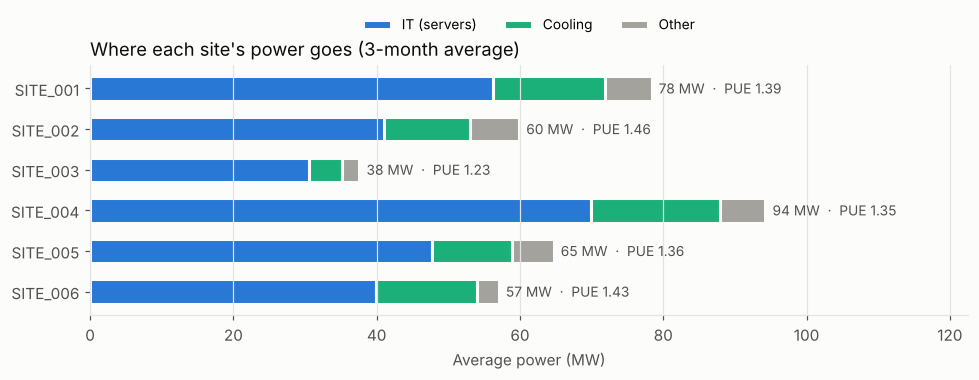

Share of all energy: {'P_IT_MW': 72.8, 'P_cool_MW': 19.3, 'P_other_MW': 7.9}


In [8]:
parts = df.groupby("site_id")[["P_IT_MW", "P_cool_MW", "P_other_MW"]].mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
left = np.zeros(len(parts))
for col, label, color in [("P_IT_MW", "IT (servers)", "#2a78d6"),
                          ("P_cool_MW", "Cooling", "#1baf7a"),
                          ("P_other_MW", "Other", "#a3a29c")]:
    ax.barh(parts.index, parts[col], left=left, color=color, label=label, height=0.6,
            edgecolor="#fcfcfb", linewidth=2)
    left += parts[col].to_numpy()
for i, (site, total) in enumerate(zip(parts.index, left)):
    ax.text(total + 1, i, f"{total:.0f} MW  ·  PUE {sites.loc[site, 'mean_PUE']:.2f}",
            va="center", fontsize=9, color=MUTED)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, left.max() * 1.3); ax.set_xlabel("Average power (MW)")
ax.set_title("Where each site's power goes (3-month average)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), ncols=3, fontsize=9)
plt.tight_layout(); plt.show()

share = df[["P_IT_MW", "P_cool_MW", "P_other_MW"]].sum() / df.P_total_MW.sum()
print("Share of all energy:", (share * 100).round(1).to_dict())

**Takeaway:**
- **The sites differ a lot in size.** SITE_004 averages about 94 MW and SITE_003 about 38 MW, so `site_id` will be an important model input.
- **About 73% of all energy goes to IT, 19% to cooling and 8% to everything else.**
- **The "legacy_stressed" sites (002 and 006) are the least efficient**, with average PUE around 1.43–1.46 against 1.23–1.39 for modern sites. Older cooling equipment needs more overhead for the same IT work.

## 5. How does demand change over the three months?

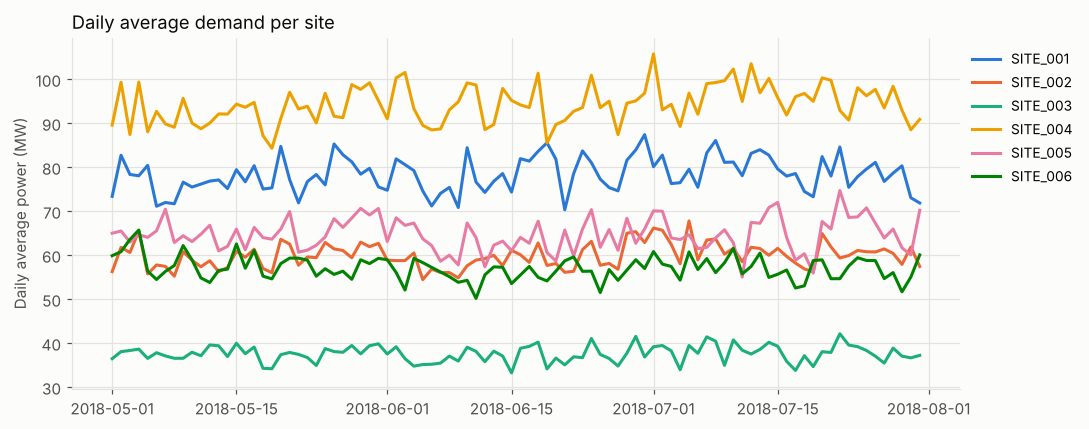

In [9]:
daily = df.set_index("timestamp").groupby("site_id").P_total_MW.resample("D").mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 4))
for site in daily.columns:
    ax.plot(daily.index, daily[site], color=SITE_COLORS[site], lw=2, label=site)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9)
ax.set_ylabel("Daily average power (MW)")
ax.set_title("Daily average demand per site")
plt.tight_layout(); plt.show()

**Takeaway:**
- **The sites keep their order throughout**: the big sites stay big.
- **No site trends steadily up or down** over the three months. Demand moves around a stable level.
- **The day-to-day wobbles often line up across sites.** That points to a shared driver, and the obvious candidate is the weather, which all six sites share (section 7).

## 6. What does a typical day and week look like?

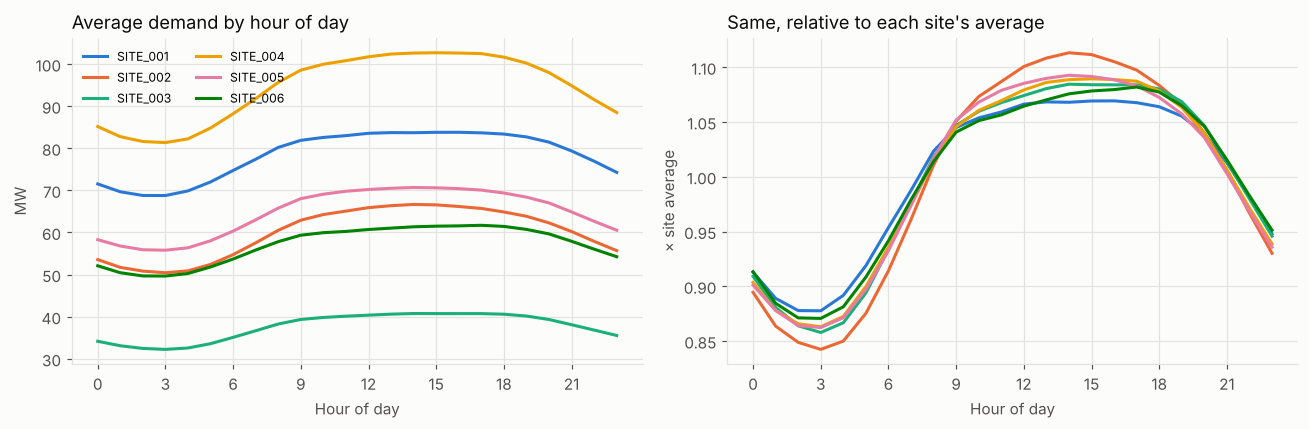

site_id,SITE_001,SITE_002,SITE_003,SITE_004,SITE_005,SITE_006
peak_hour,16.00,14.00,14.00,15.00,14.00,17.00
lowest_hour,3.00,3.00,3.00,3.00,3.00,3.00
peak ÷ lowest,1.22,1.32,1.26,1.26,1.27,1.24


In [10]:
by_hour = df.groupby(["hour", "site_id"]).P_total_MW.mean().unstack()
by_hour_rel = by_hour / by_hour.mean()        # scale each site to its own average, so shapes are comparable

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for site in by_hour.columns:
    axes[0].plot(by_hour.index, by_hour[site], color=SITE_COLORS[site], lw=2, label=site)
    axes[1].plot(by_hour.index, by_hour_rel[site], color=SITE_COLORS[site], lw=2)
axes[0].set_title("Average demand by hour of day"); axes[0].set_ylabel("MW")
axes[1].set_title("Same, relative to each site's average"); axes[1].set_ylabel("× site average")
for ax in axes:
    ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Hour of day")
axes[0].legend(ncols=2, fontsize=8)
plt.tight_layout(); plt.show()

pd.DataFrame({"peak_hour": by_hour.idxmax(), "lowest_hour": by_hour.idxmin(),
              "peak ÷ lowest": (by_hour.max() / by_hour.min()).round(2)}).T

In [11]:
dow = df.groupby("day_of_week").P_total_MW.mean().round(2)
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Average demand by day of week (MW, all sites):")
dow.to_frame().T

Average demand by day of week (MW, all sites):


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
P_total_MW,65.41,64.61,64.48,65.38,65.11,65.65,66.5


**Takeaway:**
- **Every site follows the same daily rhythm.** Demand is lowest around 03:00 and peaks in the early-to-mid afternoon (14:00–17:00). The peak is 22–32% above the overnight low.
- **The day of the week matters much less.** Daily averages differ by only about 2 MW across the week.
- So the hour of day is a key input, and so is the value from the **same hour yesterday**: it captures the daily rhythm automatically.

## 7. How does weather affect demand and efficiency?

All sites share one weather feed, so it's shown once.

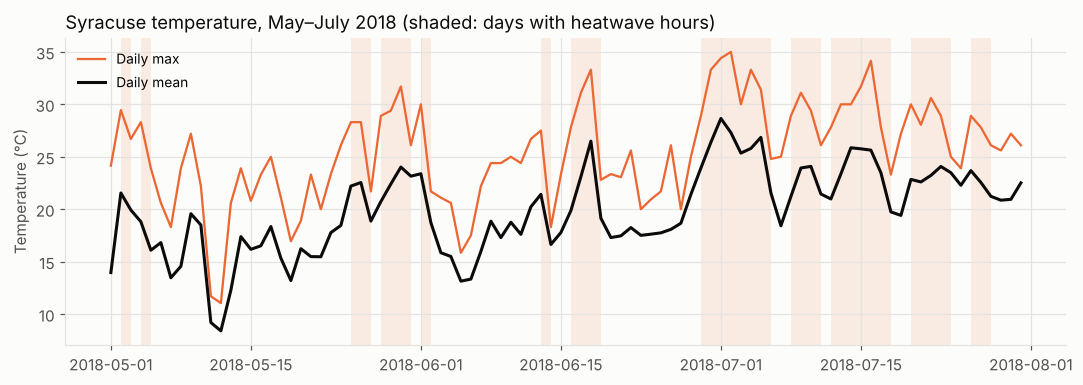

Temperature range: 0.55–35.0 °C, mean 19.8 °C
Heatwave hours: 214 across 34 days


In [12]:
weather = df.drop_duplicates("timestamp").set_index("timestamp")
wd = weather.temp_C.resample("D").agg(["mean", "max"])
hw_days = weather.heatwave_flag.resample("D").max()

fig, ax = plt.subplots(figsize=(10, 3.6))
for day in hw_days[hw_days == 1].index:
    ax.axvspan(day, day + pd.Timedelta(days=1), color="#eb6834", alpha=0.12, lw=0)
ax.plot(wd.index, wd["max"], color="#eb6834", lw=1.5, label="Daily max")
ax.plot(wd.index, wd["mean"], color=INK, lw=2, label="Daily mean")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Syracuse temperature, May–July 2018 (shaded: days with heatwave hours)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

print(f"Temperature range: {weather.temp_C.min()}–{weather.temp_C.max()} °C, mean {weather.temp_C.mean():.1f} °C")
print(f"Heatwave hours: {int(weather.heatwave_flag.sum())} across {int(hw_days.sum())} days")

It gets warmer through the summer. Heatwave spells start in late May and become longer and more frequent from late June.

Next: what happens to PUE and demand as temperature rises? The chart below groups hours into 2 °C temperature bands and plots each site's average in each band. Grouping smooths out the noise and makes the shape of the relationship visible.

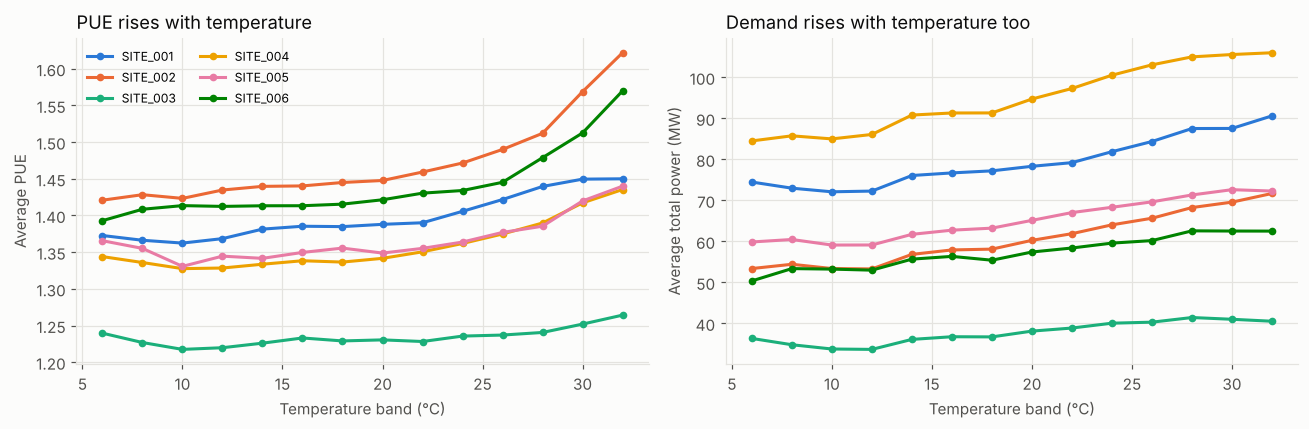

In [13]:
df["temp_band"] = (df.temp_C // 2) * 2
banded = df.groupby(["temp_band", "site_id"])[["PUE", "P_total_MW"]].mean().unstack()
counts = df.drop_duplicates("timestamp").groupby("temp_band").size()
banded = banded[counts.reindex(banded.index) >= 20]   # drop bands with fewer than 20 hours

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for site in SITE_COLORS:
    axes[0].plot(banded.index, banded[("PUE", site)], color=SITE_COLORS[site], lw=2, marker="o", ms=4, label=site)
    axes[1].plot(banded.index, banded[("P_total_MW", site)], color=SITE_COLORS[site], lw=2, marker="o", ms=4)
axes[0].set_title("PUE rises with temperature"); axes[0].set_ylabel("Average PUE")
axes[1].set_title("Demand rises with temperature too"); axes[1].set_ylabel("Average total power (MW)")
for ax in axes: ax.set_xlabel("Temperature band (°C)")
axes[0].legend(ncols=2, fontsize=8)
plt.tight_layout(); plt.show()

In [14]:
per_site_corr = pd.DataFrame({
    "corr(temp, total power)": {s: g.temp_C.corr(g.P_total_MW) for s, g in df.groupby("site_id")},
    "corr(temp, PUE)": {s: g.temp_C.corr(g.PUE) for s, g in df.groupby("site_id")},
}).round(2)
print("All sites pooled together: corr(temp, total power) =", round(df.temp_C.corr(df.P_total_MW), 2))
per_site_corr

All sites pooled together: corr(temp, total power) = 0.2


,"corr(temp, total power)","corr(temp, PUE)"
SITE_001,0.57,0.42
SITE_002,0.67,0.63
SITE_003,0.56,0.24
SITE_004,0.63,0.57
SITE_005,0.54,0.22
SITE_006,0.50,0.59


**Takeaway:**
- **Heat makes sites less efficient.** PUE climbs steadily with temperature at every site, because cooling has to work harder. During heatwave hours, average PUE is 1.42 against 1.36 otherwise.
- **Demand rises with temperature as well.** But hot hours are also afternoon hours, when IT load is high anyway, so part of this link is the daily rhythm rather than the heat itself.
- **Watch how you measure correlation.** Pooled across all sites, temperature and demand correlate at only about 0.2. Within each site, the correlation is much stronger (see the table). Pooling hides the link because the large differences in site size swamp the effect of weather. **Analyse each site separately, or give the model `site_id`.**
- Weather is worth including as a model input, especially for PUE.

## 8. How much does PUE vary within each site?

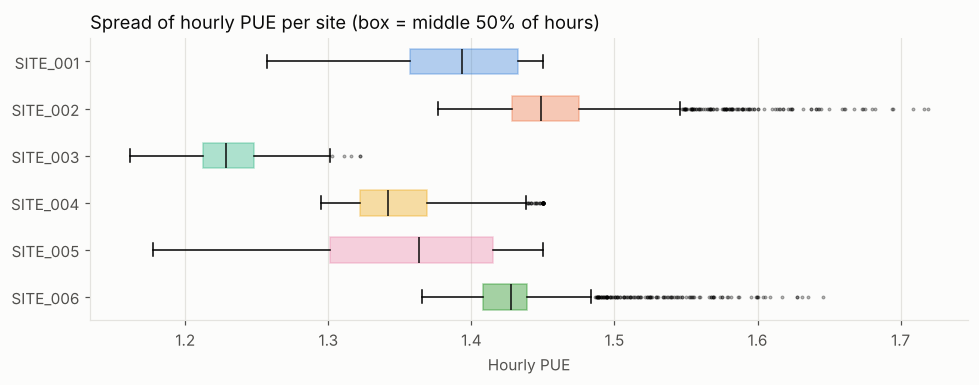

,mean,min,50%,max
site_id,,,,
SITE_001,1.391,1.257,1.393,1.450
SITE_002,1.457,1.377,1.449,1.719
SITE_003,1.231,1.161,1.229,1.322
SITE_004,1.348,1.295,1.341,1.450
SITE_005,1.357,1.177,1.364,1.450
SITE_006,1.428,1.365,1.428,1.646


In [15]:
fig, ax = plt.subplots(figsize=(9, 3.6))
order = list(SITE_COLORS)
bp = ax.boxplot([df.loc[df.site_id == s, "PUE"] for s in order], positions=range(len(order)),
                **({"orientation": "horizontal"} if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10) else {"vert": False}),
                patch_artist=True, widths=0.55, flierprops=dict(marker=".", ms=3, alpha=0.4))
ax.set_yticks(range(len(order)), order)
for patch, s in zip(bp["boxes"], order):
    patch.set_facecolor(SITE_COLORS[s]); patch.set_alpha(0.35); patch.set_edgecolor(SITE_COLORS[s])
for med in bp["medians"]: med.set_color(INK)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("Hourly PUE"); ax.set_title("Spread of hourly PUE per site (box = middle 50% of hours)")
plt.tight_layout(); plt.show()

df.groupby("site_id").PUE.describe()[["mean", "min", "50%", "max"]].round(3)

**Takeaway:**
- **Each site has its own typical PUE.** SITE_003 runs around 1.23 and SITE_002 around 1.46.
- **The legacy sites (002 and 006) have the highest values**, a long tail reaching 1.65–1.72 on their hottest hours. They handle heat less well.
- Because each site has a stable typical level, yesterday's PUE at a site is a strong starting point for forecasting today's.

## 9. What is the `regime` column?

`regime` labels each site-day with a workload pattern:
- `business_peak`
- `personal_peak`
- `load_shifted`
- `training_heavy_flat`

The first check is whether it ever changes during a day.

In [16]:
print("Most regimes seen at one site on one day:",
      int(df.groupby(["site_id", df.timestamp.dt.date]).regime.nunique().max()))
print("\nDays per regime at each site:")
(df.groupby(["site_id", "regime"]).size().unstack(fill_value=0) // 24)

Most regimes seen at one site on one day: 1

Days per regime at each site:


regime,business_peak,load_shifted,personal_peak,training_heavy_flat
site_id,,,,
SITE_001,24,48,0,20
SITE_002,76,10,5,1
SITE_003,42,0,50,0
SITE_004,34,12,19,27
SITE_005,44,9,7,32
SITE_006,23,35,21,13


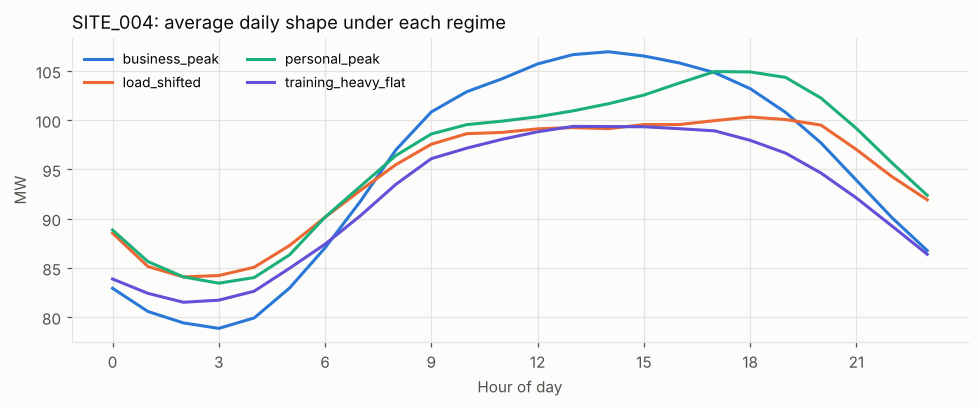

In [17]:
site = "SITE_004"   # the one site that runs all four regimes on a meaningful number of days
prof = df[df.site_id == site].groupby(["regime", "hour"]).P_total_MW.mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 3.8))
for color, r in zip(["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"], prof.columns):
    ax.plot(prof.index, prof[r], lw=2, color=color, label=r)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Hour of day"); ax.set_ylabel("MW")
ax.set_title(f"{site}: average daily shape under each regime")
ax.legend(fontsize=9, ncols=2)
plt.tight_layout(); plt.show()

**Takeaway:**
- **A regime always lasts a whole day**, like a daily operating plan.
- **Sites use regimes very differently.** SITE_003 only ever runs two regimes; SITE_004 runs all four.
- **Regimes change *when* the peak happens.** At SITE_004, business-peak days peak around 14:00, personal-peak days around 17:00–18:00, and the load-shifted and training-heavy days are flatter. The differences are a few MW, small next to the tens of MW between sites.

Whether a regime is known in advance is unclear, so it was **tested in modelling rather than assumed useful**. In that test it didn't improve demand forecasts, so the final model leaves it out.

## 10. How much does demand repeat itself?

**Autocorrelation** measures how similar a series is to itself shifted back by some number of hours:
- 1 means the same pattern repeats exactly.
- 0 means no relationship.

High autocorrelation at a given lag means the past is a good guide to the future at that distance.

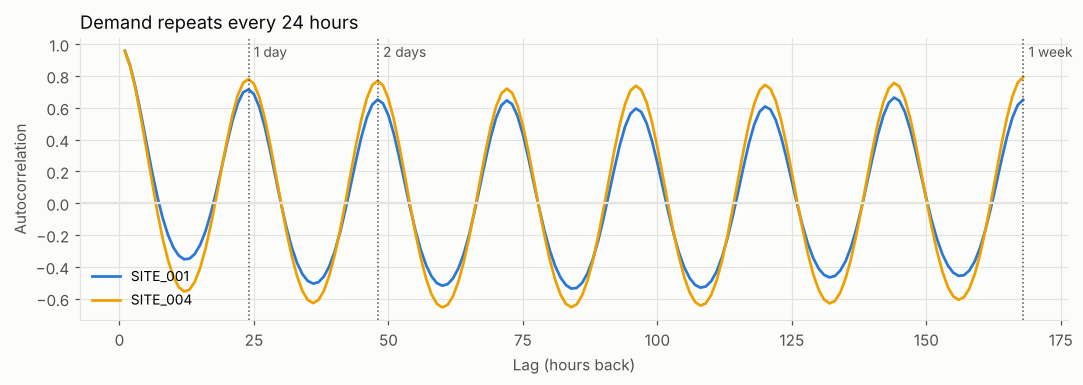

,1h,6h,12h,24h,48h,168h
SITE_004,0.96,0.14,-0.56,0.78,0.77,0.79


In [18]:
lags = range(1, 169)
fig, ax = plt.subplots(figsize=(10, 3.6))
for site in ["SITE_001", "SITE_004"]:
    s = df[df.site_id == site].set_index("timestamp").P_total_MW
    ax.plot(list(lags), [s.autocorr(l) for l in lags], color=SITE_COLORS[site], lw=1.8, label=site)
for l, txt in [(24, "1 day"), (48, "2 days"), (168, "1 week")]:
    ax.axvline(l, color=MUTED, lw=1, ls=":"); ax.text(l + 1, 0.92, txt, fontsize=9, color=MUTED)
ax.axhline(0, color=GRID)
ax.set_xlabel("Lag (hours back)"); ax.set_ylabel("Autocorrelation")
ax.set_title("Demand repeats every 24 hours")
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

s = df[df.site_id == "SITE_004"].set_index("timestamp").P_total_MW
pd.Series({f"{l}h": round(s.autocorr(l), 2) for l in [1, 6, 12, 24, 48, 168]}, name="SITE_004").to_frame().T

**Takeaway:**
- **Demand one hour ago is the best single guide (about 0.96).** But at midnight, when tomorrow's forecast is made, tomorrow's previous hour hasn't happened yet, so this lag can't be used.
- **The pattern turns negative at about 12 hours** (night compared with day) and **peaks again every 24 hours**. The values 1 day, 2 days and 1 week back are all strongly related (0.65–0.79).
- These become the model's **lag features**. "Same hour yesterday" also serves as the **baseline** the model has to beat.

## 11. Which columns could a forecast use?

Before modelling, ask of every column: **would I know this value at midnight, before the day I'm forecasting?**

In [19]:
cols = ["P_IT_MW", "P_cool_MW", "P_other_MW", "u_it_frac", "temp_C", "dewpoint_C", "rh_pct",
        "heatwave_intensity", "hour", "is_weekend"]
known = {"P_IT_MW": "No: measured in the same hour", "P_cool_MW": "No: measured in the same hour",
         "P_other_MW": "No: measured in the same hour", "u_it_frac": "No: measured in the same hour",
         "temp_C": "Yes, from a weather forecast", "dewpoint_C": "Yes, from a weather forecast",
         "rh_pct": "Yes, from a weather forecast", "heatwave_intensity": "Yes, from a weather forecast",
         "hour": "Yes, it's the calendar", "is_weekend": "Yes, it's the calendar"}
corr = pd.DataFrame({
    "corr with total power (within site, avg)": [np.mean([g[c].corr(g.P_total_MW) for _, g in df.groupby("site_id")]) for c in cols],
    "known at midnight?": [known[c] for c in cols],
}, index=cols).round(2)
corr.sort_values("corr with total power (within site, avg)", ascending=False)

,"corr with total power (within site, avg)",known at midnight?
P_IT_MW,0.95,No: measured in the same hour
u_it_frac,0.95,No: measured in the same hour
P_cool_MW,0.86,No: measured in the same hour
temp_C,0.58,"Yes, from a weather forecast"
hour,0.51,"Yes, it's the calendar"
P_other_MW,0.49,No: measured in the same hour
heatwave_intensity,0.31,"Yes, from a weather forecast"
dewpoint_C,0.22,"Yes, from a weather forecast"
is_weekend,0.07,"Yes, it's the calendar"
rh_pct,-0.43,"Yes, from a weather forecast"


**Takeaway:**
- **The most strongly correlated columns can't be used.** IT, cooling and other power are parts of the total, measured at the same moment, so they would hand the model the answer. A model trained on them would look nearly perfect in testing and be useless in practice, because tomorrow's IT load isn't known tonight. This mistake is called **data leakage**.
- **The usable inputs are:**
  - past load (lags of 24 hours or more)
  - calendar information
  - site identity
  - weather (in real use, from a weather forecast)

## 12. Summary: what the data told us

| Finding | Evidence | Modelling decision |
|---|---|---|
| Clean, complete hourly data | Section 2: no nulls, duplicates or gaps | Lag features can use simple row shifts |
| Power columns obey exact identities | Section 3 | Use them as data quality rules; never as inputs |
| Sites differ greatly in size and efficiency | Sections 4 and 8 | Give the model `site_id`; train one model across all sites |
| Strong daily cycle, weak weekly cycle | Sections 6 and 10 | Hour-of-day and same-hour-yesterday features; yesterday is the baseline |
| Heat raises PUE and demand | Section 7 | Include weather, especially for PUE |
| Pooling sites hides relationships | Section 7 | Analyse per site |
| Regime is a whole-day label with small effects | Section 9 | Test it rather than assume; it was later dropped |
| Same-hour components would leak the answer | Sections 3 and 11 | Exclude them from the features |

**The forecasting task that follows from this:**

> At midnight, predict each site's power demand and PUE for every hour of the next day, using only the past, the calendar, the site and the weather forecast.

The pipeline in `src/dcforecast/` builds exactly that. See the project README for the results.